In [1]:
import numpy as np

In [2]:
np.random.seed(42)

## LogisticRegression

In [4]:
class LogisticRegression:
    def __init__(self,lr=0.01,n_iter= 10000):
        self.lr = lr
        self.n_iter = n_iter
        self.w = None
        self.b = None
        self.cost_history = []
    def fit(self,x,y):
        self.x = x
        self.y = y
        self.m,self.n = self.x.shape
        #intitialize parameters
        self.initialize_parameters()
        for i in range(self.n_iter):
            # forward propagation
            y_pred = self.forward_propagation()
            # compute cost
            cost = self.compute_cost(y_pred)
            self.cost_history.append(cost)
            # back propagation
            dw,db = self.backward_propagation(y_pred)
            # update parameters
            self.update_parameters(dw,db)
            if i%100==0:
                print(f"Iteration:{i},   Cost: {cost:.4f}")

    def initialize_parameters(self):
        self.w = np.random.rand(self.n) * 0.01
        self.b = 0
    def sigmoid(self,z):
        return 1/(1+np.exp(-z))
    def forward_propagation(self):
        z = np.dot(self.x,self.w) + self.b
        y_pred = self.sigmoid(z)
        return y_pred
    def compute_cost(self,y_pred):
        # add small epsilon to avoid log(0) errors
        epsilon = 1e-15
        y_pred = np.clip(y_pred,epsilon,1-epsilon)  # np.clip(array, min_value, max_value)
        cost = -(1/self.m)*np.sum(self.y*np.log(y_pred)+(1-self.y)*np.log(1-y_pred))
        return cost
    def backward_propagation(self,y_pred):
        dw = (1/self.m) * np.dot(self.x.T,(y_pred-self.y))
        db = (1/self.m) * np.sum(y_pred-self.y)
        return dw,db
    def update_parameters(self,dw,db):
        self.w -= (self.lr*dw)
        self.b -= (self.lr*db)
    def predict(self,x,threshold = 0.5):
        z = np.dot(x,self.w) + self.b
        y_pred = self.sigmoid(z) 
        # if x contains multiple samples, y_pred is an array of probabilities
        return (y_pred > threshold).astype(int) # return a numpy array  # also wrire like: return [1 if i > threshold else 0 for i in y_pred]
    

In [5]:
## RegularizedLogisticRegression

In [6]:
class RegularizedLogisticRegression:
    def __init__(self,lr=0.01,n_iter= 10000,penalty=None,lambda_reg=0.1):
        self.lr = lr
        self.n_iter = n_iter
        self.w = None
        self.b = None
        self.cost_history = []
        self.lambda_reg = lambda_reg
        self.penalty = penalty  # penalty is string : None, 'l1' or 'l2'
    def fit(self,x,y):
        self.x = x
        self.y = y
        self.m,self.n = self.x.shape
        #intitialize parameters
        self.initialize_parameters()
        for i in range(self.n_iter):
            # forward propagation
            y_pred = self.forward_propagation()
            # compute cost
            cost = self.compute_cost(y_pred)
            self.cost_history.append(cost)
            # back propagation
            dw,db = self.backward_propagation(y_pred)
            # update parameters
            self.update_parameters(dw,db)
            if i%100==0:
                print(f"Iteration:{i},   Cost: {cost:.4f}")

    def initialize_parameters(self):
        self.w = np.random.rand(self.n) * 0.01
        self.b = 0
    def sigmoid(self,z):
        return 1/(1+np.exp(-z))
    def forward_propagation(self):
        z = np.dot(self.x,self.w) + self.b
        y_pred = self.sigmoid(z)
        return y_pred
    def compute_cost(self,y_pred):
        # add small epsilon to avoid log(0) errors
        epsilon = 1e-15
        y_pred = np.clip(y_pred,epsilon,1-epsilon)  # np.clip(array, min_value, max_value)
        cost = -(1/self.m)*np.sum(self.y*np.log(y_pred)+(1-self.y)*np.log(1-y_pred))
        # add rugularizations
        if self.penalty == 'l2':
            # Ridge: (lambda / 2m) * sum(w^2)
            cost += (self.lambda_reg/(2*self.m))* np.sum(self.w**2)
        elif self.penalty == 'l1':
            # Lasso: (lambda / m) * sum(|w|)
            cost += (self.lambda_reg/self.m)* np.sum(np.abs(self.w))
        return cost
    def backward_propagation(self,y_pred):
        dw = (1/self.m) * np.dot(self.x.T,(y_pred-self.y))
        db = (1/self.m) * np.sum(y_pred-self.y)
        if self.penalty == 'l2':
            # Derivative of w^2 is 2w. The 2 cancels out with the 1/2 in cost.
            # Gradient: (lambda / m) * w
            dw += (self.lambda_reg/self.m)*self.w
        elif self.penalty == 'l1':
            # Derivative of |w| is sign(w)
            # Gradient: (lambda / m) * sign(w)
            dw += (self.lambda_reg/self.m)* np.sign(self.w)
        return dw,db
    def update_parameters(self,dw,db):
        self.w -= (self.lr*dw)
        self.b -= (self.lr*db)
    def predict(self,x,threshold = 0.5):
        z = np.dot(x,self.w) + self.b
        y_pred = self.sigmoid(z) 
        # if x contains multiple samples, y_pred is an array of probabilities
        return (y_pred > threshold).astype(int) # return a numpy array  # also wrire like: return [1 if i > threshold else 0 for i in y_pred]
    

In [36]:
# below code directly copied from gemini to generate sample data

In [8]:
# Generate small dataset to encourage overfitting
n_samples = 50
# Two classes with some overlap (noise)
X_class0 = np.random.randn(n_samples//2, 2) + 1.5
X_class1 = np.random.randn(n_samples//2, 2) + 5.5

# Add outlier points to confuse the model
X_outliers = np.array([[6, 1], [1, 6], [2, 5]])
y_outliers = np.array([0, 1, 1])

X_train = np.vstack((X_class0, X_class1, X_outliers))
y_train = np.hstack((np.zeros(n_samples//2), np.ones(n_samples//2), y_outliers))

print(f"Data shape: {X_train.shape}")

Data shape: (53, 2)


In [9]:
X_train[:5]

array([[1.99671415, 1.3617357 ],
       [2.14768854, 3.02302986],
       [1.26584663, 1.26586304],
       [3.07921282, 2.26743473],
       [1.03052561, 2.04256004]])

In [10]:
y_train[:5]

array([0., 0., 0., 0., 0.])

In [12]:
model = LogisticRegression(lr=0.01, n_iter=10000)
model.fit(X_train,y_train)

Iteration:0,   Cost: 0.6868
Iteration:100,   Cost: 0.5042
Iteration:200,   Cost: 0.4623
Iteration:300,   Cost: 0.4272
Iteration:400,   Cost: 0.3970
Iteration:500,   Cost: 0.3709
Iteration:600,   Cost: 0.3480
Iteration:700,   Cost: 0.3277
Iteration:800,   Cost: 0.3097
Iteration:900,   Cost: 0.2936
Iteration:1000,   Cost: 0.2791
Iteration:1100,   Cost: 0.2659
Iteration:1200,   Cost: 0.2540
Iteration:1300,   Cost: 0.2432
Iteration:1400,   Cost: 0.2333
Iteration:1500,   Cost: 0.2242
Iteration:1600,   Cost: 0.2158
Iteration:1700,   Cost: 0.2081
Iteration:1800,   Cost: 0.2010
Iteration:1900,   Cost: 0.1944
Iteration:2000,   Cost: 0.1882
Iteration:2100,   Cost: 0.1825
Iteration:2200,   Cost: 0.1771
Iteration:2300,   Cost: 0.1721
Iteration:2400,   Cost: 0.1674
Iteration:2500,   Cost: 0.1630
Iteration:2600,   Cost: 0.1588
Iteration:2700,   Cost: 0.1549
Iteration:2800,   Cost: 0.1512
Iteration:2900,   Cost: 0.1477
Iteration:3000,   Cost: 0.1443
Iteration:3100,   Cost: 0.1412
Iteration:3200,   Co

In [13]:
model.w

array([0.4459022 , 1.25908565])

In [14]:
model_l2 = RegularizedLogisticRegression(lr=0.01,n_iter=10000,penalty='l2',lambda_reg=2.0)
model_l2.fit(X_train,y_train)

Iteration:0,   Cost: 0.6882
Iteration:100,   Cost: 0.5056
Iteration:200,   Cost: 0.4649
Iteration:300,   Cost: 0.4308
Iteration:400,   Cost: 0.4016
Iteration:500,   Cost: 0.3763
Iteration:600,   Cost: 0.3541
Iteration:700,   Cost: 0.3345
Iteration:800,   Cost: 0.3171
Iteration:900,   Cost: 0.3016
Iteration:1000,   Cost: 0.2877
Iteration:1100,   Cost: 0.2751
Iteration:1200,   Cost: 0.2638
Iteration:1300,   Cost: 0.2535
Iteration:1400,   Cost: 0.2441
Iteration:1500,   Cost: 0.2355
Iteration:1600,   Cost: 0.2277
Iteration:1700,   Cost: 0.2205
Iteration:1800,   Cost: 0.2138
Iteration:1900,   Cost: 0.2077
Iteration:2000,   Cost: 0.2020
Iteration:2100,   Cost: 0.1967
Iteration:2200,   Cost: 0.1918
Iteration:2300,   Cost: 0.1873
Iteration:2400,   Cost: 0.1830
Iteration:2500,   Cost: 0.1790
Iteration:2600,   Cost: 0.1753
Iteration:2700,   Cost: 0.1718
Iteration:2800,   Cost: 0.1685
Iteration:2900,   Cost: 0.1654
Iteration:3000,   Cost: 0.1625
Iteration:3100,   Cost: 0.1597
Iteration:3200,   Co

In [15]:
model_l2.w

array([0.47994902, 1.07487566])

In [18]:
#compare model, model_l2
print("weights:")
print("model: ",model.w)
print("model_l2: ",model_l2.w)

weights:
model:  [0.4459022  1.25908565]
model_l2:  [0.47994902 1.07487566]


In [19]:
print("bias:")
print("model: ",model.b)
print("model_l2: ",model_l2.b)

bias:
model:  -5.345491068301743
model_l2:  -4.97120268001458


l2 weights are small

In [20]:
import matplotlib.pyplot as plt

In [24]:
def plot_boundary(model, X, y, ax, title):
    # Plot data points
    ax.scatter(X[y==0][:, 0], X[y==0][:, 1], color='red', alpha=0.6, label='Class 0')
    ax.scatter(X[y==1][:, 0], X[y==1][:, 1], color='blue', alpha=0.6, label='Class 1')
    
    # Plot decision boundary
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x1_vals = np.linspace(x1_min, x1_max, 100)
    w1, w2 = model.w
    b = model.b
    # Decision boundary: w1*x1 + w2*x2 + b = 0
    x2_vals = -(w1 * x1_vals + b) / w2
    
    ax.plot(x1_vals, x2_vals, 'k--', linewidth=2)
    ax.set_title(title)
    ax.set_ylim(X[:, 1].min()-1, X[:, 1].max()+1)
    ax.legend()

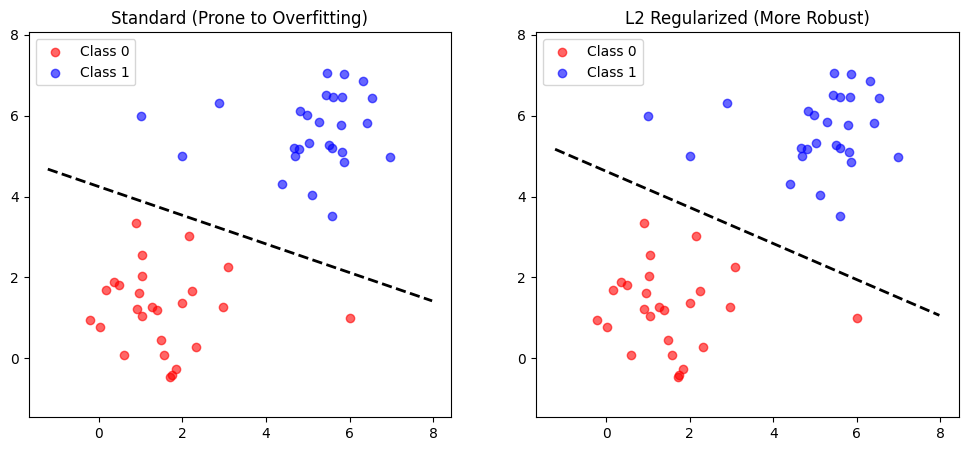

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_boundary(model, X_train, y_train, axes[0], "Standard (Prone to Overfitting)")
plot_boundary(model_l2, X_train, y_train, axes[1], "L2 Regularized (More Robust)")
plt.show()

Exercise 1: Feature Selection with L1

Create a dataset with 10 features, where only 2 are actually useful (the rest are noise). Train an L1 model and check if the weights for the 8 noise features go to zero.

In [26]:
# Generate data with 2 useful features and 8 noise features
n = 100
X_useful = np.random.randn(n, 2)
X_noise = np.random.randn(n, 8) # Pure noise
X_combined = np.hstack((X_useful, X_noise))

# y depends ONLY on the first 2 features
true_w = np.array([2.5, -3.0])
y_combined = (np.dot(X_useful, true_w) > 0).astype(int)

In [29]:
y_combined[:3]

array([0, 1, 1])

In [30]:
model_l1 = RegularizedLogisticRegression(lr=0.1,n_iter=10000,penalty='l1',lambda_reg=5.0)
model_l1.fit(X_combined,y_combined)

Iteration:0,   Cost: 0.6954
Iteration:100,   Cost: 0.4256
Iteration:200,   Cost: 0.4036
Iteration:300,   Cost: 0.3981
Iteration:400,   Cost: 0.3963
Iteration:500,   Cost: 0.3956
Iteration:600,   Cost: 0.3951
Iteration:700,   Cost: 0.3948
Iteration:800,   Cost: 0.3947
Iteration:900,   Cost: 0.3948
Iteration:1000,   Cost: 0.3951
Iteration:1100,   Cost: 0.3947
Iteration:1200,   Cost: 0.3949
Iteration:1300,   Cost: 0.3946
Iteration:1400,   Cost: 0.3947
Iteration:1500,   Cost: 0.3944
Iteration:1600,   Cost: 0.3945
Iteration:1700,   Cost: 0.3946
Iteration:1800,   Cost: 0.3950
Iteration:1900,   Cost: 0.3950
Iteration:2000,   Cost: 0.3948
Iteration:2100,   Cost: 0.3946
Iteration:2200,   Cost: 0.3945
Iteration:2300,   Cost: 0.3945
Iteration:2400,   Cost: 0.3944
Iteration:2500,   Cost: 0.3946
Iteration:2600,   Cost: 0.3948
Iteration:2700,   Cost: 0.3951
Iteration:2800,   Cost: 0.3949
Iteration:2900,   Cost: 0.3945
Iteration:3000,   Cost: 0.3945
Iteration:3100,   Cost: 0.3945
Iteration:3200,   Co

In [35]:
np.round(model_l1.w,3).astype(int)

array([ 1, -1,  0,  0,  0,  0,  0,  0,  0,  0])